# M5 Demand Forecasting - Notebook 03: LightGBM model

**Goal:** beat the best baseline from notebook 02, and understand *where* and *why* the model wins or loses.

Run `python -m src.run_lgbm` first. It trains the model and writes the tables read here.

**How the model works (short version)**
- **One global model** for all item-store series, forecasting each of the next 28 days directly. The horizon (1 to 28) is a feature, so there is no recursive forecasting.
- **Features:** recent sales (lags, rolling means, zero rate, days since last sale), same-weekday averages, price and price changes, calendar, events, SNAP, and static labels (store, department, category). Everything is known at the forecast origin, plus the calendar and price of the target day, which are known in advance.
- **Loss:** Tweedie (power 1.1), a standard choice for sales data with many zeros.
- **Backtest:** the same 3 origins and the same evaluated series as notebook 02, so the numbers are directly comparable. For each origin, training uses only targets that end before the validation window, and validation ends before the test window. The model never sees its own test period.

**Interactive tables:** tables below can be sorted, searched and filtered (needs `itables`; otherwise they show as plain tables).

**Sections:** 1) Training log, 2) Target to beat, 3) Accuracy by segment, 4) Accuracy by day ahead, 5) Aggregate level, 6) What drives the forecast, 7) Example forecasts, 8) Series scoreboard (prototype for the web), 9) Key findings

In [25]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import config
from src.viz import show_table, save_table

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
config.FIG_DIR.mkdir(parents=True, exist_ok=True)
H = config.HORIZON
BASE = ["naive", "seasonal_naive", "seasonal_avg_4w", "moving_avg_28d", "croston_sba"]

def save(fig, name):
    fig.savefig(config.FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

T = config.TABLES_DIR
need = ["lgbm_metrics.csv", "baseline_metrics.csv", "lgbm_horizon_metrics.csv", "lgbm_aggregate_metrics.csv",
        "aggregate_metrics.csv", "lgbm_training_log.csv", "series_segments.csv", "lgbm_forecasts_last_origin.csv.gz"]
missing = [f for f in need if not (T / f).exists()]
if missing:
    raise FileNotFoundError(f"Missing {missing} in {T}.\nRun first in a terminal: python -m src.run_week2 and then python -m src.run_lgbm")

lgb = pd.read_csv(T / "lgbm_metrics.csv")
base = pd.read_csv(T / "baseline_metrics.csv")
hor = pd.read_csv(T / "lgbm_horizon_metrics.csv")
agg_l = pd.read_csv(T / "lgbm_aggregate_metrics.csv")
agg_b = pd.read_csv(T / "aggregate_metrics.csv")
tlog = pd.read_csv(T / "lgbm_training_log.csv")
seg = pd.read_csv(T / "series_segments.csv")
fc = pd.read_csv(T / "lgbm_forecasts_last_origin.csv.gz", parse_dates=["date"])
base_all = base[(base["scope"] == "all") & base["method"].isin(BASE)]

if (tlog["backend"] != "lightgbm").any():
    print("WARNING: these results come from the scikit-learn TEST fallback, not LightGBM. Do not report them.")
print(f"{len(seg):,} series | origins: {sorted(lgb['origin'].unique())}")

12,196 series | origins: [np.int64(1), np.int64(2), np.int64(3)]


## 1. Training log

One model per backtest origin. `best_iteration` is the number of trees chosen by early stopping on the validation window.

In [26]:
show_table(tlog)

## 2. Target to beat

The comparison is made on the **same series and the same 3 origins** as notebook 02. The best baseline is the one with the lowest RMSSE.

Best baseline: moving_avg_28d
  WAPE    baseline 0.751 -> lightgbm 0.729  (+2.9% better)
  RMSSE   baseline 0.756 -> lightgbm 0.742  (+1.8% better)
  wRMSSE  baseline 0.864 -> lightgbm 0.820  (+5.2% better)
  Bias    baseline -0.021 -> lightgbm -0.007


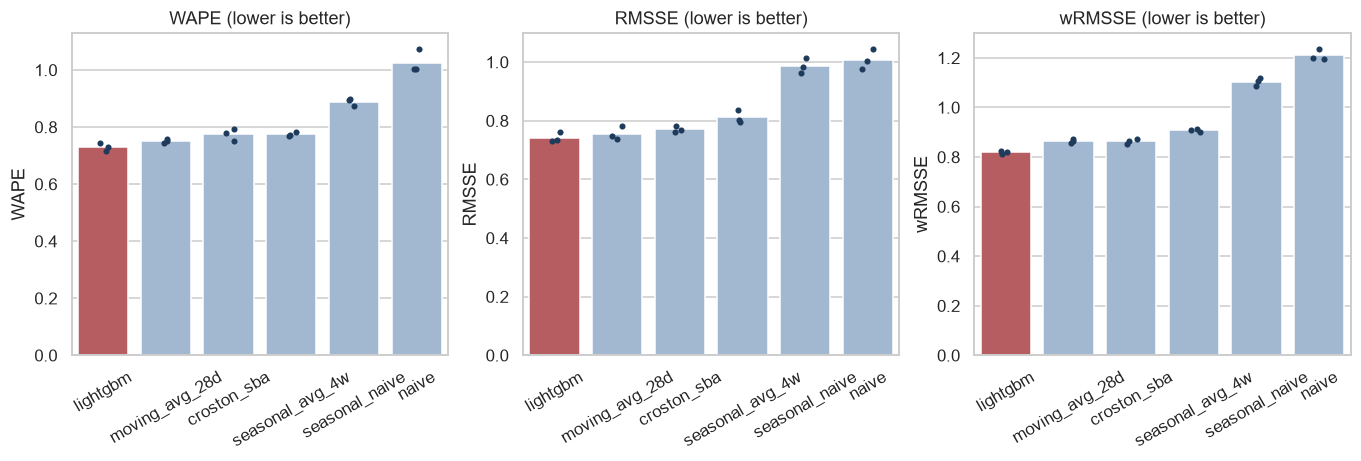

In [27]:
ov = pd.concat([base_all[base_all["level"] == "all"], lgb[lgb["level"] == "all"]], ignore_index=True)
tbl = ov.groupby("method")[["WAPE", "Bias", "RMSSE", "wRMSSE"]].mean().sort_values("RMSSE")
best_name = [m for m in tbl.index if m in BASE][0]
best, mine = tbl.loc[best_name], tbl.loc["lightgbm"]

overall = tbl.round(3).reset_index()
show_table(overall)
print(f"Best baseline: {best_name}")
for metric in ["WAPE", "RMSSE", "wRMSSE"]:
    print(f"  {metric:7s} baseline {best[metric]:.3f} -> lightgbm {mine[metric]:.3f}  ({100 * (best[metric] - mine[metric]) / best[metric]:+.1f}% better)")
print(f"  Bias    baseline {best['Bias']:+.3f} -> lightgbm {mine['Bias']:+.3f}")

order = tbl.index.tolist()
palette = {m: ("#c44e52" if m == "lightgbm" else "#9ab7d8") for m in order}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, metric in zip(axes, ["WAPE", "RMSSE", "wRMSSE"]):
    sns.barplot(data=ov, x="method", y=metric, order=order, palette=palette, hue="method", legend=False, errorbar=None, ax=ax)
    sns.stripplot(data=ov, x="method", y=metric, order=order, color="#1f3b5c", size=4, ax=ax)
    ax.set(title=f"{metric} (lower is better)", xlabel=""); ax.tick_params(axis="x", rotation=30)
save(fig, "18_model_vs_baselines"); plt.show()

## 3. Accuracy by segment

For each segment the model is compared with the **best baseline for that segment** (lowest RMSSE), so the bar is set as high as possible. Positive improvement means LightGBM is better.

In [28]:
def compare(level):
    b = (base_all[base_all["level"] == level].groupby(["group", "method"])
         .agg(RMSSE=("RMSSE", "mean"), WAPE=("WAPE", "mean"), n_series=("n_series", "mean")).reset_index())
    best = b.loc[b.groupby("group")["RMSSE"].idxmin()].rename(
        columns={"method": "best_baseline", "RMSSE": "base_RMSSE", "WAPE": "base_WAPE"})
    l = (lgb[lgb["level"] == level].groupby("group")
         .agg(lgb_RMSSE=("RMSSE", "mean"), lgb_WAPE=("WAPE", "mean"), lgb_Bias=("Bias", "mean")).reset_index())
    out = best.merge(l, on="group")
    out["RMSSE_improvement_pct"] = 100 * (out["base_RMSSE"] - out["lgb_RMSSE"]) / out["base_RMSSE"]
    out["WAPE_improvement_pct"] = 100 * (out["base_WAPE"] - out["lgb_WAPE"]) / out["base_WAPE"]
    out.insert(0, "level", level)
    return out[["level", "group", "n_series", "best_baseline", "base_RMSSE", "lgb_RMSSE", "RMSSE_improvement_pct",
                "base_WAPE", "lgb_WAPE", "WAPE_improvement_pct", "lgb_Bias"]]

levels = ["demand_pattern", "abc", "xyz", "abc_xyz", "cat_id", "store_id"]
by_seg = pd.concat([compare(l) for l in levels], ignore_index=True)
by_seg["n_series"] = by_seg["n_series"].round(0).astype(int)
by_seg = by_seg.round(3)
show_table(by_seg)

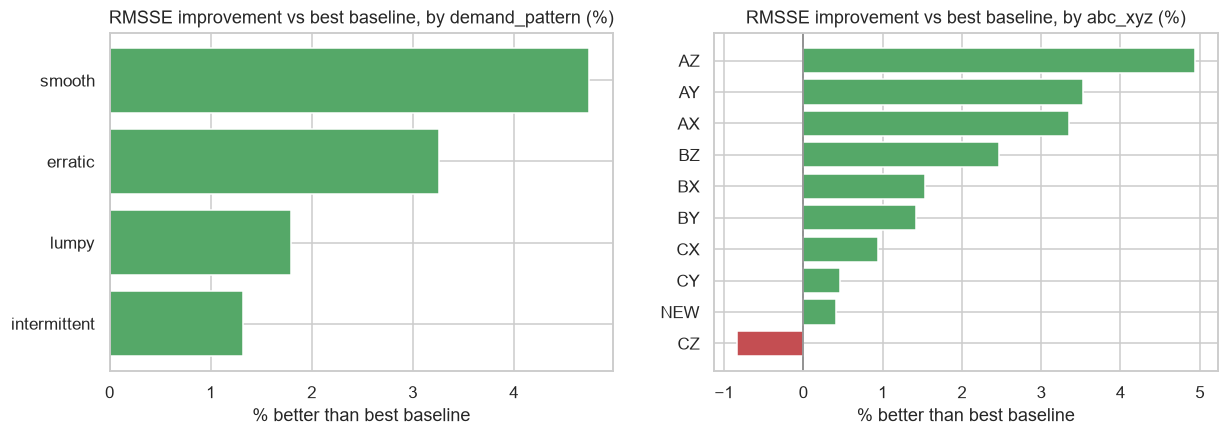

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, level in zip(axes, ["demand_pattern", "abc_xyz"]):
    d = by_seg[(by_seg["level"] == level) & (by_seg["group"] != "no_demand")].sort_values("RMSSE_improvement_pct")
    colors = ["#55a868" if v >= 0 else "#c44e52" for v in d["RMSSE_improvement_pct"]]
    ax.barh(d["group"], d["RMSSE_improvement_pct"], color=colors)
    ax.axvline(0, color="grey", lw=1)
    ax.set(title=f"RMSSE improvement vs best baseline, by {level} (%)", xlabel="% better than best baseline", ylabel="")
save(fig, "19_improvement_by_segment"); plt.show()

## 4. Accuracy by day ahead

Forecasts usually get worse the further ahead we look. A good model should lose less than the baselines.

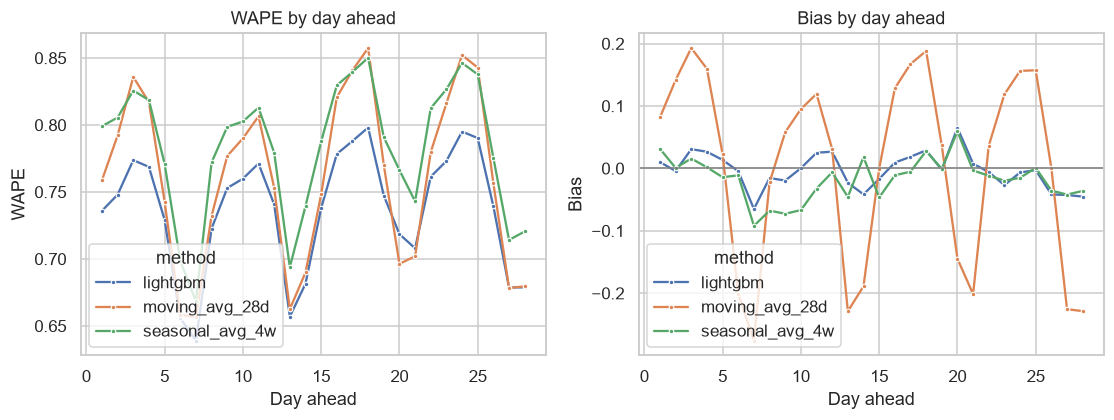

In [29]:
hh = hor.groupby(["method", "h"])[["WAPE", "Bias"]].mean().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.lineplot(data=hh, x="h", y="WAPE", hue="method", marker="o", ms=3, ax=axes[0]); axes[0].set(title="WAPE by day ahead", xlabel="Day ahead")
sns.lineplot(data=hh, x="h", y="Bias", hue="method", marker="o", ms=3, ax=axes[1]); axes[1].axhline(0, color="grey", lw=1); axes[1].set(title="Bias by day ahead", xlabel="Day ahead")
save(fig, "20_accuracy_by_horizon"); plt.show()
show_table(hh.round(4))

## 5. Aggregate level

The item-level forecasts are added up (bottom-up) to store x category and total level, and compared with the statistical models from notebook 02 that were fitted directly on those totals. This is the view a category or warehouse planner cares about.

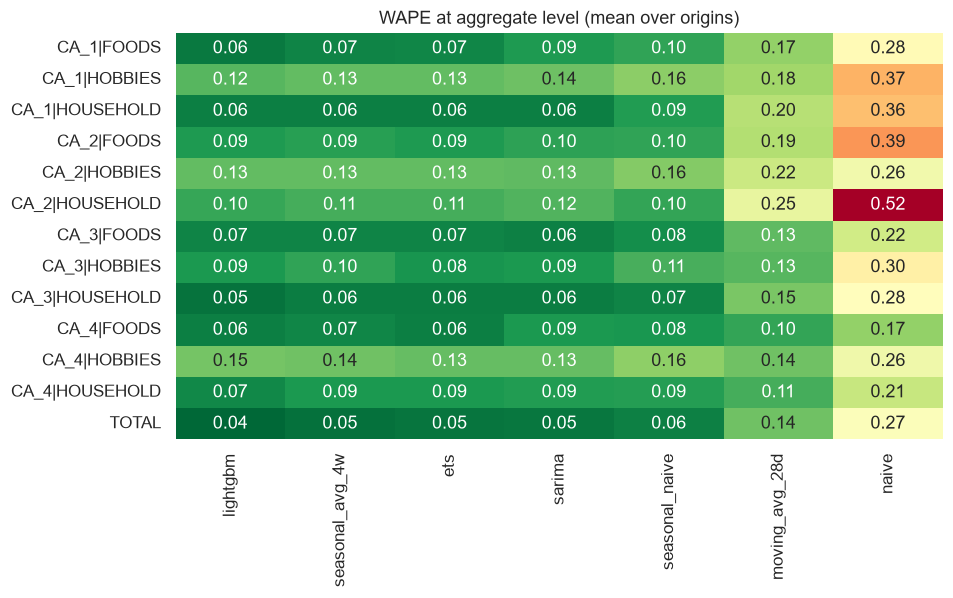

In [30]:
agg_all = pd.concat([agg_b, agg_l], ignore_index=True)
t = agg_all.groupby(["group", "method"])["WAPE"].mean().unstack("method")
t = t[t.loc["TOTAL"].sort_values().index]
show_table(t.round(3).reset_index())

fig, ax = plt.subplots(figsize=(9, 4.8))
sns.heatmap(t, annot=True, fmt=".2f", cmap="RdYlGn_r", cbar=False, ax=ax)
ax.set(title="WAPE at aggregate level (mean over origins)", xlabel="", ylabel="")
save(fig, "21_aggregate_wape_with_lgbm"); plt.show()

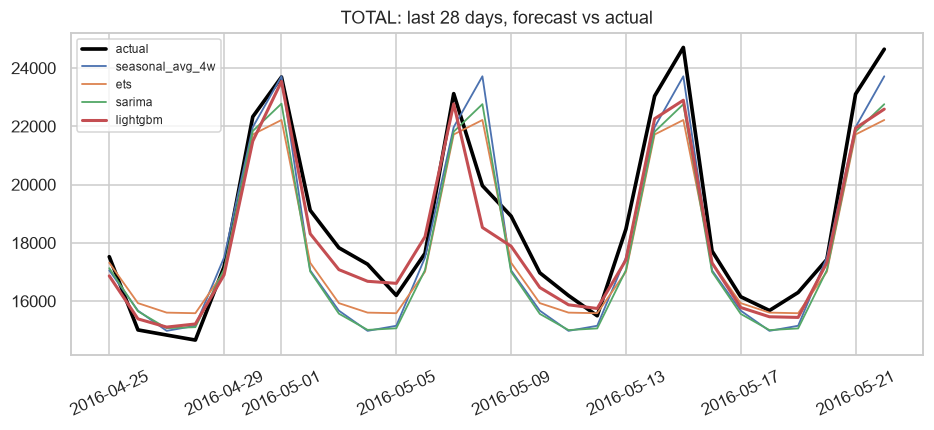

In [31]:
fcb = pd.read_csv(T / "aggregate_forecasts.csv", parse_dates=["date"])
fcl = pd.read_csv(T / "lgbm_aggregate_forecasts.csv", parse_dates=["date"])
last_o = fcl["origin"].max()
d = pd.concat([fcb[fcb["origin"] == last_o], fcl[fcl["origin"] == last_o]], ignore_index=True)
d = d[d["group"] == "TOTAL"]
fig, ax = plt.subplots(figsize=(10, 3.8))
act = d[d["method"] == "lightgbm"]
ax.plot(act["date"], act["actual"], color="black", lw=2.4, label="actual")
for m in [x for x in ["seasonal_avg_4w", "ets", "sarima", "lightgbm"] if x in d["method"].unique()]:
    dd = d[d["method"] == m]
    ax.plot(dd["date"], dd["forecast"], lw=2 if m == "lightgbm" else 1.2, label=m)
ax.set(title="TOTAL: last 28 days, forecast vs actual"); ax.legend(fontsize=8); ax.tick_params(axis="x", rotation=25)
save(fig, "22_total_forecast_vs_actual"); plt.show()

## 6. What drives the forecast

- **Gain importance** shows which features the trees used most.
- **SHAP** shows how much each feature pushes a single forecast up or down. LightGBM computes SHAP values itself. They are in log space (the Tweedie link), so a value of +0.10 means roughly +10% on the forecast.

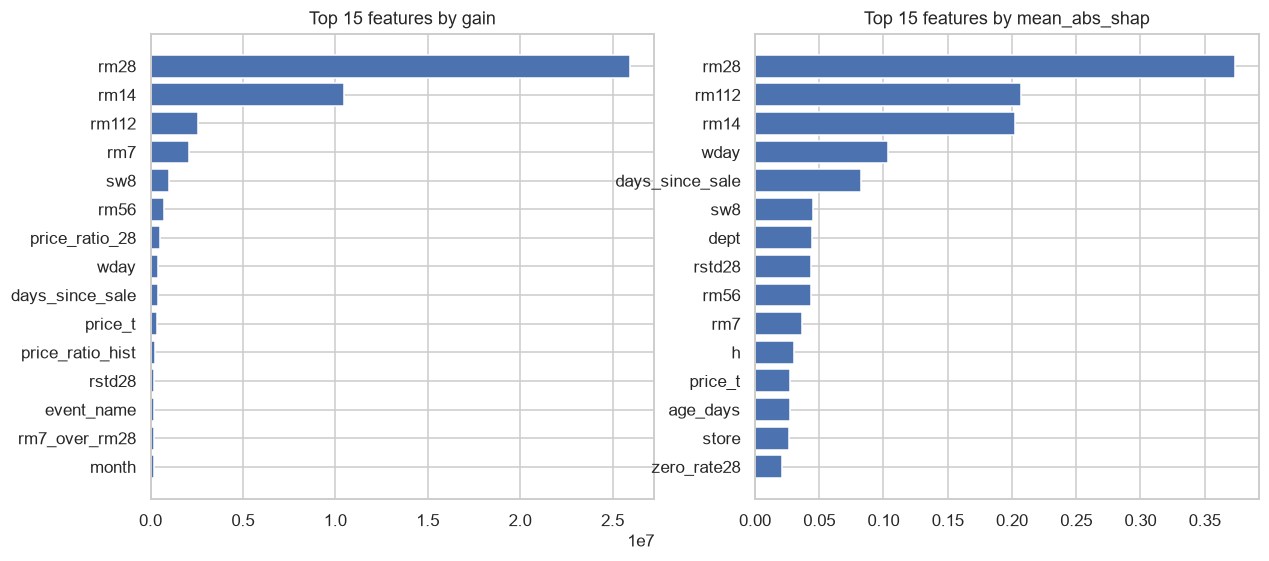

In [32]:
imp_path = T / "lgbm_feature_importance.csv"
shap_path = config.PROCESSED_DIR / "lgbm_shap_sample.npz"
if imp_path.exists():
    imp = pd.read_csv(imp_path)
    show_table(imp.round(3))
    cols = [c for c in ["gain", "mean_abs_shap"] if c in imp.columns]
    fig, axes = plt.subplots(1, len(cols), figsize=(6.5 * len(cols), 5.5), squeeze=False)
    for ax, col in zip(axes[0], cols):
        d = imp.sort_values(col, ascending=False).head(15).iloc[::-1]
        ax.barh(d["feature"], d[col], color="#4c72b0"); ax.set(title=f"Top 15 features by {col}")
    save(fig, "23_feature_importance"); plt.show()
else:
    print("No importance table (the test fallback has none). Run with LightGBM installed.")

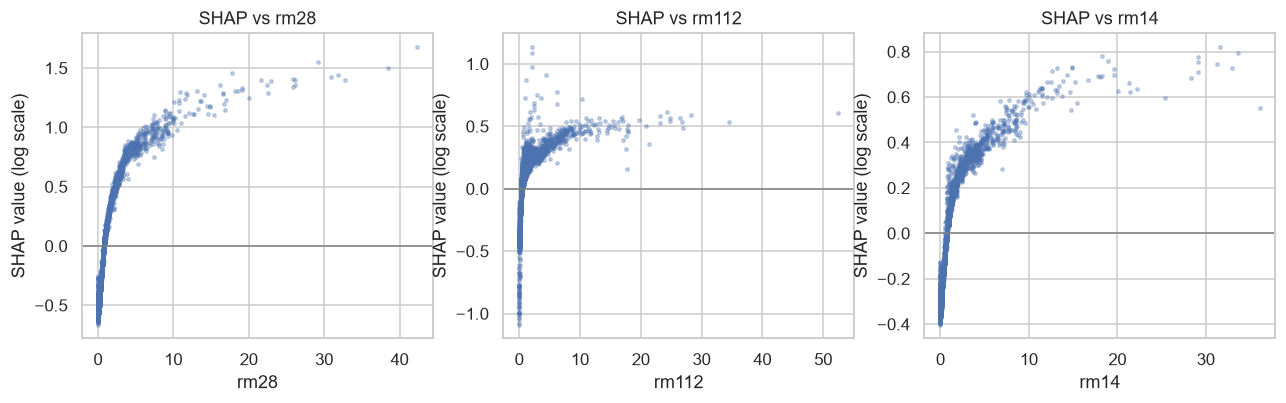

In [33]:
if shap_path.exists():
    z = np.load(shap_path)
    X, S, feats = z["X"], z["shap"][:, :-1], list(z["features"])
    top = np.argsort(-np.abs(S).mean(axis=0))[:3]
    take = np.random.default_rng(0).choice(len(X), size=min(4000, len(X)), replace=False)
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
    for ax, j in zip(axes, top):
        ax.scatter(X[take, j], S[take, j], s=5, alpha=0.3, color="#4c72b0")
        ax.axhline(0, color="grey", lw=1); ax.set(title=f"SHAP vs {feats[j]}", xlabel=feats[j], ylabel="SHAP value (log scale)")
    save(fig, "24_shap_dependence"); plt.show()
else:
    print("No SHAP sample found.")

## 7. Example forecasts

The most valuable series of each demand pattern, last 28 days. Compare LightGBM with the 28-day moving average (the best simple baseline in notebook 02).

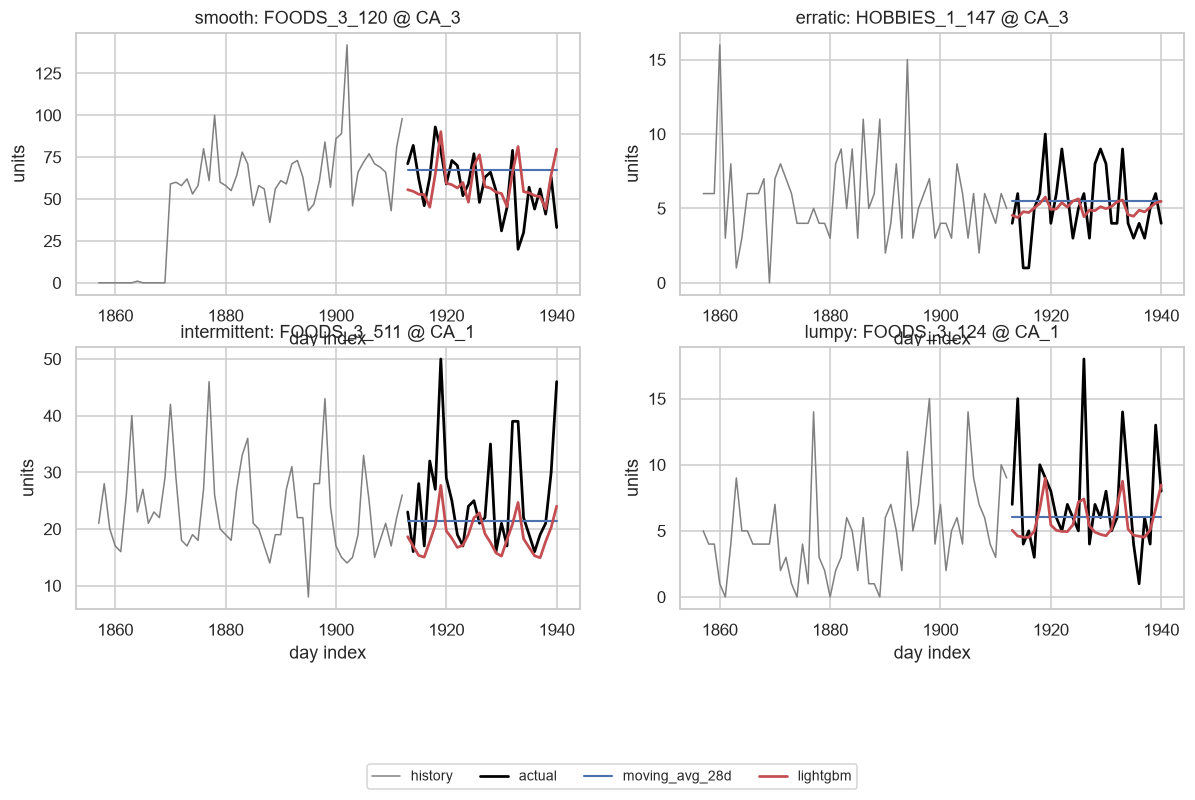

In [34]:
from src.data_access import load_sales_data, masked_float
from src.baselines import BASELINES

data = load_sales_data(verbose=False)
Yf = masked_float(data)
c = data.n_days - H
ma = np.nan_to_num(BASELINES["moving_avg_28d"](Yf, c, H), nan=0.0)

patterns = [p for p in ["smooth", "erratic", "intermittent", "lumpy"] if (seg["demand_pattern"] == p).any()]
n_rows = max(1, int(np.ceil(len(patterns) / 2)))
fig, axes = plt.subplots(n_rows, 2, figsize=(13, 3.4 * n_rows), squeeze=False)
have = set(fc["series_id"].unique())
for ax, p in zip(axes.ravel(), patterns):
    cand = seg[(seg["demand_pattern"] == p) & (seg["abc_xyz"] != "NEW") & seg["series_id"].isin(have)]
    cand = cand.sort_values("revenue_window", ascending=False)
    if cand.empty:
        continue
    i = cand.index[0]
    f = fc[fc["series_id"] == seg.loc[i, "series_id"]].sort_values("h")
    hist_x, fut_x = np.arange(c - 56, c), np.arange(c, c + H)
    ax.plot(hist_x, data.Y[i, c - 56:c], color="grey", lw=1, label="history")
    ax.plot(fut_x, data.Y[i, c:c + H], color="black", lw=1.8, label="actual")
    ax.plot(fut_x, ma[i], lw=1.4, label="moving_avg_28d")
    ax.plot(fut_x, f["forecast"].to_numpy(), lw=1.8, color="#c44e52", label="lightgbm")
    ax.set(title=f"{p}: {seg.loc[i, 'item_id']} @ {seg.loc[i, 'store_id']}", xlabel="day index", ylabel="units")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=9, bbox_to_anchor=(0.5, -0.14))
for ax in axes.ravel()[len(patterns):]:
    ax.axis("off")
save(fig, "25_example_forecasts_lgbm"); plt.show()

## 8. Series scoreboard (prototype for the web)

One row per item-store series for the last 28 days: actual vs forecast, error, and segment. Filter by store, category or segment, sort by error, and search for an item. **The web dashboard will use this same table**, so it is saved as CSV and as JSON in `dashboard/data/`.

In [35]:
f = fc.assign(abs_err=(fc["forecast"] - fc["actual"]).abs())
sc = (f.groupby("series_id").agg(actual_28d=("actual", "sum"), forecast_28d=("forecast", "sum"),
                                 abs_err_28d=("abs_err", "sum")).reset_index())
sc["wape_28d"] = np.where(sc["actual_28d"] > 0, sc["abs_err_28d"] / sc["actual_28d"], np.nan)
sc["bias_pct"] = np.where(sc["actual_28d"] > 0, 100 * (sc["forecast_28d"] - sc["actual_28d"]) / sc["actual_28d"], np.nan)
sc = sc.merge(seg[["series_id", "item_id", "store_id", "cat_id", "dept_id", "abc_xyz", "demand_pattern"]], on="series_id")
sc = sc[["series_id", "item_id", "store_id", "cat_id", "dept_id", "abc_xyz", "demand_pattern",
         "actual_28d", "forecast_28d", "abs_err_28d", "wape_28d", "bias_pct"]].round(3)
sc = sc.sort_values("abs_err_28d", ascending=False).reset_index(drop=True)
show_table(sc)

saved = []
saved += save_table(sc, "series_scoreboard")
saved += save_table(overall, "model_comparison_overall")
saved += save_table(by_seg, "model_comparison_by_segment")
print("Saved for the web and for reuse:")
for p in saved:
    print("  ", p.relative_to(config.ROOT))

Saved for the web and for reuse:
   reports\tables\series_scoreboard.csv
   dashboard\data\series_scoreboard.json
   reports\tables\model_comparison_overall.csv
   dashboard\data\model_comparison_overall.json
   reports\tables\model_comparison_by_segment.csv
   dashboard\data\model_comparison_by_segment.json


## 9. Key findings (fill in after running on the real M5 data)

Write 6-8 bullets with numbers from your own tables:

- **Headline:** by how much does LightGBM beat the best baseline on WAPE, RMSSE and wRMSSE? Is the gain consistent across the 3 origins?
- **Where it wins most:** which demand patterns and ABC-XYZ cells improve most? Does the gain concentrate in the high-revenue A series?
- **Where it does not win:** any segment where a simple baseline is as good or better? What does that say about the data?
- **Bias:** does the model over- or under-forecast anywhere? What would that mean for stock (too much cash tied up, or stockouts)?
- **Horizon:** how fast does accuracy fall from day 1 to day 28, compared with the baselines?
- **Aggregate level:** is the bottom-up total as good as ETS/SARIMA fitted directly on the total?
- **Drivers:** which features matter most (recent level, same-weekday average, price, events)? Does that match business intuition?
- **Limits:** what is not captured (new items, promotions not in the data, supply constraints)?

**Next (notebook 04):** turn these forecasts into inventory decisions: safety stock, reorder points, and the cost of stockouts vs overstock compared with the baseline forecast.

*(Replace this cell with your own findings.)*